In [1]:

from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver

In [2]:
load_dotenv()
llm = ChatGoogleGenerativeAI(model="gemini-flash-lite-latest", max_tokens=1000)

In [3]:
class JokeState(TypedDict):

    topic: str
    joke: str
    explanation: str

In [4]:
def generate_joke(state: JokeState):

    prompt = f'generate a joke on the topic {state["topic"]}'
    response = llm.invoke(prompt).content

    return {'joke': response}

In [5]:
def generate_explanation(state: JokeState):

    prompt = f'write an explanation for the joke - {state["joke"]}'
    response = llm.invoke(prompt).content

    return {'explanation': response}

In [6]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('generate_explanation', generate_explanation)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'generate_explanation')
graph.add_edge('generate_explanation', END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

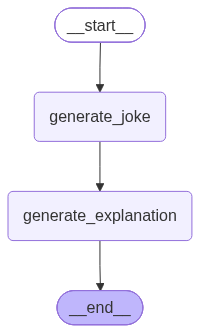

In [7]:
workflow

In [8]:
config1 = {"configurable": {"thread_id": "1"}}
workflow.invoke({'topic':'pizza'}, config=config1)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


{'topic': 'pizza',
 'joke': [{'type': 'text',
   'text': 'Why did the hipster burn his mouth on the pizza?\n\nBecause he ate it before it was cool.',
   'extras': {'signature': 'EmAKXgFpFH0TjYejHeNSNLHJgy7ThC6/2AOGxfisqRSEphjhEGKc+C4+UzUJtHWRXBSJtkHLdQpGV/gouGt2XvUnWm6Vq7BZ7ZKXrX2EVP4ivbTbw2kCcygVRA0HghVHfSI='}}],
 'explanation': [{'type': 'text',
   'text': 'This joke relies on a play on words regarding the slang definition of the word **"cool."**\n\nHere is the breakdown of the humor:\n\n1. **The Stereotype:** "Hipsters" are a subculture known for trying to be overly trendy and ahead of the curve. A common cliché associated with hipsters is that they like to discover bands, coffee shops, or trends *before* they become popular, often saying things like, "I liked them before they were cool."\n2. **The Literal Meaning:** In the context of food, when something is "hot," you have to wait for it to **"cool"** down before you can eat it safely without burning your mouth. \n\n**The Punchline

## Time Travel

In [9]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'pizza', 'joke': [{'type': 'text', 'text': 'Why did the hipster burn his mouth on the pizza?\n\nBecause he ate it before it was cool.', 'extras': {'signature': 'EmAKXgFpFH0TjYejHeNSNLHJgy7ThC6/2AOGxfisqRSEphjhEGKc+C4+UzUJtHWRXBSJtkHLdQpGV/gouGt2XvUnWm6Vq7BZ7ZKXrX2EVP4ivbTbw2kCcygVRA0HghVHfSI='}}], 'explanation': [{'type': 'text', 'text': 'This joke relies on a play on words regarding the slang definition of the word **"cool."**\n\nHere is the breakdown of the humor:\n\n1. **The Stereotype:** "Hipsters" are a subculture known for trying to be overly trendy and ahead of the curve. A common cliché associated with hipsters is that they like to discover bands, coffee shops, or trends *before* they become popular, often saying things like, "I liked them before they were cool."\n2. **The Literal Meaning:** In the context of food, when something is "hot," you have to wait for it to **"cool"** down before you can eat it safely without burning your mouth. \n\n**The

In [11]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': [{'type': 'text', 'text': 'Why did the hipster burn his mouth on the pizza?\n\nBecause he ate it before it was cool.', 'extras': {'signature': 'EmAKXgFpFH0TjYejHeNSNLHJgy7ThC6/2AOGxfisqRSEphjhEGKc+C4+UzUJtHWRXBSJtkHLdQpGV/gouGt2XvUnWm6Vq7BZ7ZKXrX2EVP4ivbTbw2kCcygVRA0HghVHfSI='}}], 'explanation': [{'type': 'text', 'text': 'This joke relies on a play on words regarding the slang definition of the word **"cool."**\n\nHere is the breakdown of the humor:\n\n1. **The Stereotype:** "Hipsters" are a subculture known for trying to be overly trendy and ahead of the curve. A common cliché associated with hipsters is that they like to discover bands, coffee shops, or trends *before* they become popular, often saying things like, "I liked them before they were cool."\n2. **The Literal Meaning:** In the context of food, when something is "hot," you have to wait for it to **"cool"** down before you can eat it safely without burning your mouth. \n\n**Th

In [12]:
config2 = {"configurable": {"thread_id": "2"}}
workflow.invoke({'topic':'pasta'}, config=config2)

{'topic': 'pasta',
 'joke': [{'type': 'text',
   'text': 'What is a carb’s favorite type of music?\n\n**A-ghetti-on!** \n\n*(Okay, how about this one?)*\n\nWhy did the spaghetti go to the casino?\nIt wanted to **penne** its luck!',
   'extras': {'signature': 'EmAKXgFpFH0TzGd2AtjwTVg+byEx7GGoXsPbsD0/+b0rTqtw9nJm2r/5ZEv4pOS9bVobdEKcXVwZNP4fOBoNhj+DijADMYggzTGuY4Iz36Pu/DP0WLuiPagsKhkNmrjRtB8='}}],
 'explanation': [{'type': 'text',
   'text': 'Here is an explanation of the two-part joke:\n\n### Part 1:\n* **The Joke:** "What is a carb’s favorite type of music? A-ghetti-on!"\n* **The Explanation:** This is a play on **Reggaeton** (a very popular style of Latin urban music). The punchline replaces the "Regga-" sound with **"Spaghetti"** (specifically focusing on the "-ghetti" part), making it sound like *A-ghetti-on*. Because spaghetti is a carbohydrate, it fits the theme of the setup. \n\n---\n\n### Part 2:\n* **The Joke:** "Why did the spaghetti go to the casino? It wanted to penne its luc

In [13]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'pasta', 'joke': [{'type': 'text', 'text': 'What is a carb’s favorite type of music?\n\n**A-ghetti-on!** \n\n*(Okay, how about this one?)*\n\nWhy did the spaghetti go to the casino?\nIt wanted to **penne** its luck!', 'extras': {'signature': 'EmAKXgFpFH0TzGd2AtjwTVg+byEx7GGoXsPbsD0/+b0rTqtw9nJm2r/5ZEv4pOS9bVobdEKcXVwZNP4fOBoNhj+DijADMYggzTGuY4Iz36Pu/DP0WLuiPagsKhkNmrjRtB8='}}], 'explanation': [{'type': 'text', 'text': 'Here is an explanation of the two-part joke:\n\n### Part 1:\n* **The Joke:** "What is a carb’s favorite type of music? A-ghetti-on!"\n* **The Explanation:** This is a play on **Reggaeton** (a very popular style of Latin urban music). The punchline replaces the "Regga-" sound with **"Spaghetti"** (specifically focusing on the "-ghetti" part), making it sound like *A-ghetti-on*. Because spaghetti is a carbohydrate, it fits the theme of the setup. \n\n---\n\n### Part 2:\n* **The Joke:** "Why did the spaghetti go to the casino? It wanted to pe

In [17]:
workflow.get_state({"configurable": {"thread_id": "2", "checkpoint_id": "1f1c3609-64eb-666e-8001-712f602a42a3"}})

StateSnapshot(values={'topic': 'pasta', 'joke': [{'type': 'text', 'text': 'What is a carb’s favorite type of music?\n\n**A-ghetti-on!** \n\n*(Okay, how about this one?)*\n\nWhy did the spaghetti go to the casino?\nIt wanted to **penne** its luck!', 'extras': {'signature': 'EmAKXgFpFH0TzGd2AtjwTVg+byEx7GGoXsPbsD0/+b0rTqtw9nJm2r/5ZEv4pOS9bVobdEKcXVwZNP4fOBoNhj+DijADMYggzTGuY4Iz36Pu/DP0WLuiPagsKhkNmrjRtB8='}}]}, next=('generate_explanation',), config={'configurable': {'thread_id': '2', 'checkpoint_id': '1f1c3609-64eb-666e-8001-712f602a42a3'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-10-08T21:38:23.121343+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1c3609-5814-6b46-8000-814b0e5f9417'}}, tasks=(PregelTask(id='9f714fc2-0ae3-492f-72aa-8471866f62f3', name='generate_explanation', path=('__pregel_pull', 'generate_explanation'), error=None, interrupts=(), state=None, result={'explanation': [{'type': 'text', 'te

In [18]:
workflow.invoke(None, {"configurable": {"thread_id": "2", "checkpoint_id": "1f1c3609-64eb-666e-8001-712f602a42a3"}})

{'topic': 'pasta',
 'joke': [{'type': 'text',
   'text': 'What is a carb’s favorite type of music?\n\n**A-ghetti-on!** \n\n*(Okay, how about this one?)*\n\nWhy did the spaghetti go to the casino?\nIt wanted to **penne** its luck!',
   'extras': {'signature': 'EmAKXgFpFH0TzGd2AtjwTVg+byEx7GGoXsPbsD0/+b0rTqtw9nJm2r/5ZEv4pOS9bVobdEKcXVwZNP4fOBoNhj+DijADMYggzTGuY4Iz36Pu/DP0WLuiPagsKhkNmrjRtB8='}}],
 'explanation': [{'type': 'text',
   'text': 'This text contains two food-themed dad jokes that rely on puns (wordplay) involving pasta. Here is the explanation for both:\n\n### Joke 1:\n> **"What is a carb’s favorite type of music? A-ghetti-on!"**\n\n*   **The Setup:** Carbohydrates (like pasta, bread, and rice) are often simply called "carbs." \n*   **The Punchline:** "A-ghetti-on" is a play on the musical genre **Reggaeton** (pronounced *reh-gah-TAHN*). \n*   **The Wordplay:** The joke swaps the "Reggae" part of the genre with **"spaghetti"**, a very popular type of carbohydrate/pasta. \n\n--

In [19]:
workflow.update_state({"configurable": {"thread_id": "2", "checkpoint_id": "1f1c3609-64eb-666e-8001-712f602a42a3", "checkpoint_ns": ""}}, {'topic':'samosa'})

{'configurable': {'thread_id': '2',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1c3628-ba3a-61c6-8002-062a81267f7a'}}

In [20]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'samosa', 'joke': [{'type': 'text', 'text': 'What is a carb’s favorite type of music?\n\n**A-ghetti-on!** \n\n*(Okay, how about this one?)*\n\nWhy did the spaghetti go to the casino?\nIt wanted to **penne** its luck!', 'extras': {'signature': 'EmAKXgFpFH0TzGd2AtjwTVg+byEx7GGoXsPbsD0/+b0rTqtw9nJm2r/5ZEv4pOS9bVobdEKcXVwZNP4fOBoNhj+DijADMYggzTGuY4Iz36Pu/DP0WLuiPagsKhkNmrjRtB8='}}]}, next=('generate_explanation',), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1c3628-ba3a-61c6-8002-062a81267f7a'}}, metadata={'source': 'update', 'step': 2, 'parents': {}}, created_at='2026-10-08T21:52:24.216381+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1c3609-64eb-666e-8001-712f602a42a3'}}, tasks=(PregelTask(id='58e71c58-be38-46e5-1234-b40db9422fd0', name='generate_explanation', path=('__pregel_pull', 'generate_explanation'), error=None, interrupts=(), state=None, result=None),), int

In [21]:
workflow.invoke(None, {"configurable": {"thread_id": "2", "checkpoint_id": "1f1c3628-ba3a-61c6-8002-062a81267f7a"}})

{'topic': 'samosa',
 'joke': [{'type': 'text',
   'text': 'What is a carb’s favorite type of music?\n\n**A-ghetti-on!** \n\n*(Okay, how about this one?)*\n\nWhy did the spaghetti go to the casino?\nIt wanted to **penne** its luck!',
   'extras': {'signature': 'EmAKXgFpFH0TzGd2AtjwTVg+byEx7GGoXsPbsD0/+b0rTqtw9nJm2r/5ZEv4pOS9bVobdEKcXVwZNP4fOBoNhj+DijADMYggzTGuY4Iz36Pu/DP0WLuiPagsKhkNmrjRtB8='}}],
 'explanation': [{'type': 'text',
   'text': 'Here is an explanation of the two related food jokes:\n\n### Joke 1:\n> **What is a carb’s favorite type of music?**\n> **A-ghetti-on!**\n\n* **The Setup:** Carbohydrates (carbs) include foods like pasta, bread, and potatoes. \n* **The Punchline:** "A-ghetti-on" is a pun on **reggaeton** (a very popular genre of Latin urban music). It combines the word "spaghetti" with "reggaeton."\n\n---\n\n### Joke 2:\n> **Why did the spaghetti go to the casino?**\n> **It wanted to penne its luck!**\n\n* **The Setup:** Casinos are places where people go to gamble 